# 01 – Exploratory Data Analysis (M2)
**Project:** E-commerce Delivery & Logistics Performance Analysis

**Input:** `data/interim/orders_clean.csv` (created by `python src/clean.py`, one row per order, with quality flags)

**Charts:** the 7 views asked for in the Team Work Guide. Every chart has a title, axis labels, the order count (n), a one-line takeaway, and is saved to `reports/figures/`.

*Relationships shown here are descriptive. They are associations, not causes.*

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Paths: this notebook lives in notebooks/, so ".." is the project root
# Find the project root, whether the notebook runs from notebooks/ or from the project folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INTERIM = ROOT / "data" / "interim"
RAW = ROOT / "data" / "raw"
FIGURES = ROOT / "reports" / "figures"

# One consistent look for every chart
BLUE = "#2a78d6"      # main colour for single-series charts
ORANGE = "#eb6834"    # highlight colour for the one thing the chart is about
GREY = "#b8b7b2"      # everything else
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,      # remove chart box clutter
    "axes.axisbelow": True,                                    # grid lines behind the bars
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})

def save(fig, name):
    """Save a chart as PNG in reports/figures/."""
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")
    print("Saved:", FIGURES / name)

In [2]:
# Load the cleaned order-level data (output of src/clean.py)
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
df = pd.read_csv(INTERIM / "orders_clean.csv", parse_dates=date_cols)  # read dates as real dates

# Reviews come from raw (one row per review) for the rating chart
reviews = pd.read_csv(RAW / "olist_order_reviews_dataset.csv")

print("Orders:", f"{len(df):,}", "| unique order_id:", df["order_id"].is_unique)
print("Purchase dates:", df["order_purchase_timestamp"].min().date(), "to", df["order_purchase_timestamp"].max().date())

Orders: 99,441 | unique order_id: True
Purchase dates: 2016-09-04 to 2018-10-17


## Chart 1: Orders per month

Saved: C:\Users\charv\Documents\qveto\Ecommerce\reports\figures\01_orders_per_month.png


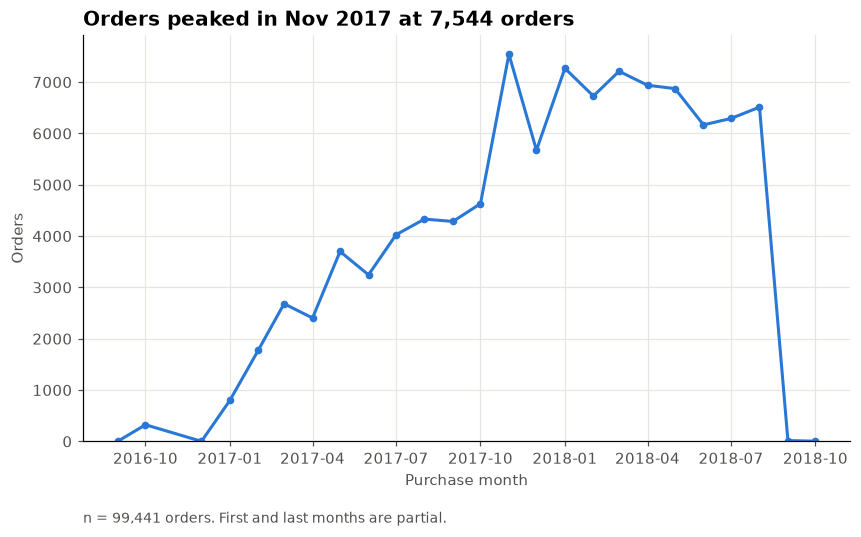

Takeaway: order volume grew over time and peaked in November 2017 (7,544 orders).
Months with fewer than 100 orders (partial or very early): ['2016-09', '2016-12', '2018-09', '2018-10']


In [3]:
# CHART 1: How many orders were placed each month?
monthly = df.groupby(df["order_purchase_timestamp"].dt.to_period("M")).size()  # count orders per month
peak_month, peak_orders = monthly.idxmax(), monthly.max()

fig, ax = plt.subplots()
ax.plot(monthly.index.to_timestamp(), monthly.values, color=BLUE, linewidth=2, marker="o", markersize=4)
ax.set_title(f"Orders peaked in {peak_month.strftime('%b %Y')} at {peak_orders:,} orders")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Orders")
ax.set_ylim(bottom=0)                                      # counts start at zero
ax.text(0, -0.2, f"n = {len(df):,} orders. First and last months are partial.",
        transform=ax.transAxes, fontsize=9, color="#52514e")
save(fig, "01_orders_per_month.png")
plt.show()

print(f"Takeaway: order volume grew over time and peaked in {peak_month.strftime('%B %Y')} ({peak_orders:,} orders).")
print("Months with fewer than 100 orders (partial or very early):", list(monthly[monthly < 100].index.astype(str)))

**Takeaway (Chart 1):** Order volume grew steadily through 2017 and peaked in **November 2017 (7,544 orders)**, the Black Friday month. The sharp drop in Sep–Oct 2018, like the very low months in 2016, marks the **edges of the dataset (partial months)**, not a real fall in demand. These months (2016-09, 2016-12, 2018-09, 2018-10, each under 100 orders) should be excluded or flagged in monthly trend KPIs.

## Chart 2: Delivery duration

Saved: C:\Users\charv\Documents\qveto\Ecommerce\reports\figures\02_delivery_duration.png


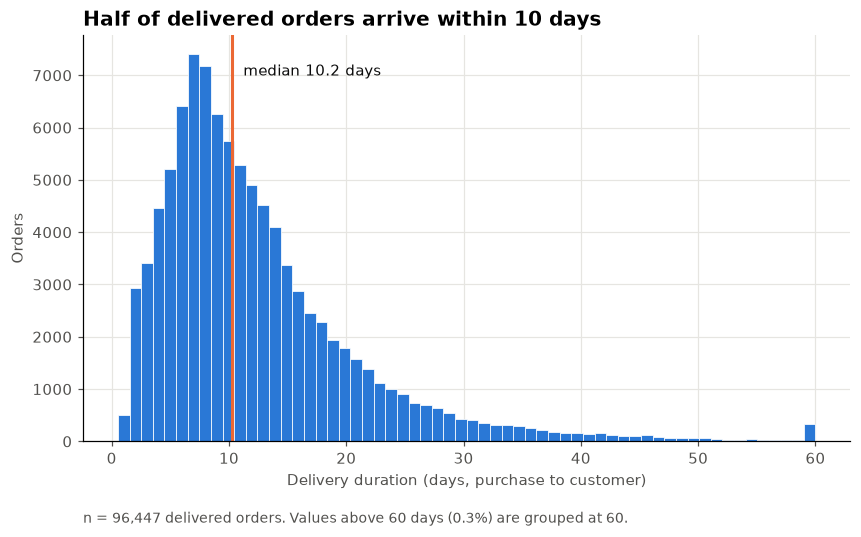

Takeaway: median delivery time is 10.2 days; the long right tail (flag_long_delivery) holds the late orders.


In [4]:
# CHART 2: How long did delivered orders take to arrive (purchase -> customer)?
# Delivered orders with a delivery date; DQ-07 orders (delivered before carrier) left out
d = df[(df["order_status"] == "delivered") & df["delivery_days"].notna() & ~df["flag_delivered_before_carrier"]]
median_days = d["delivery_days"].median()
share_late = (d["delivery_days"] > 60).mean() * 100        # share hidden by the 60-day axis cut

fig, ax = plt.subplots()
ax.hist(d["delivery_days"].clip(upper=60), bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(median_days, color=ORANGE, linewidth=2)         # mark the median
ax.text(median_days + 1, ax.get_ylim()[1] * 0.9, f"median {median_days:.1f} days", color="#0b0b0b")
ax.set_title(f"Half of delivered orders arrive within {median_days:.0f} days")
ax.set_xlabel("Delivery duration (days, purchase to customer)")
ax.set_ylabel("Orders")
ax.text(0, -0.2, f"n = {len(d):,} delivered orders. Values above 60 days ({share_late:.1f}%) are grouped at 60.",
        transform=ax.transAxes, fontsize=9, color="#52514e")
save(fig, "02_delivery_duration.png")
plt.show()

print(f"Takeaway: median delivery time is {median_days:.1f} days; the long right tail (flag_long_delivery) holds the late orders.")

**Takeaway (Chart 2):** Half of delivered orders arrive within **10.2 days** (n = 96,447). The distribution is right-skewed: most orders arrive in 5–15 days, with a long tail of slow deliveries. Those are the 4,896 orders flagged `flag_long_delivery` and the main focus for delay analysis (M4).

## Chart 3: Processing time

Saved: C:\Users\charv\Documents\qveto\Ecommerce\reports\figures\03_processing_time.png


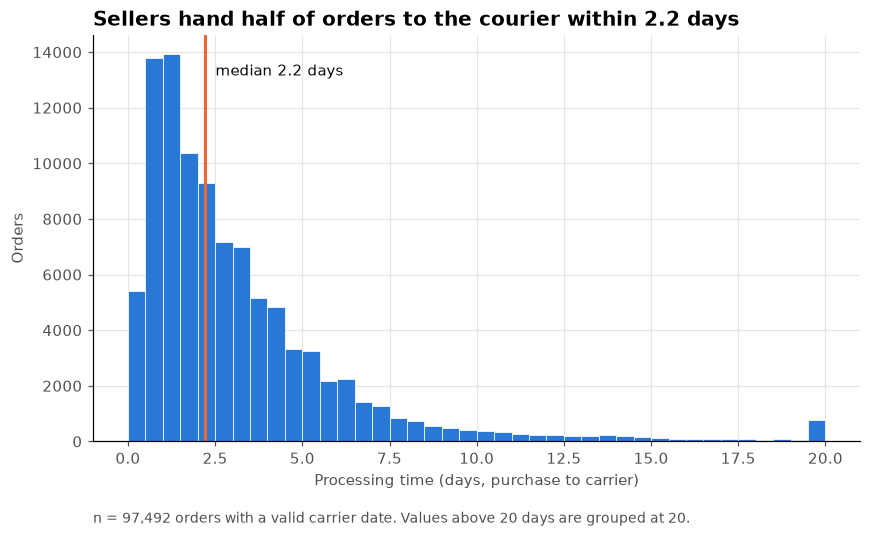

Takeaway: median processing time is 2.2 days, much shorter than total delivery time, so most of the wait is in transit.


In [5]:
# CHART 3: How long did sellers take to hand orders to the courier (purchase -> carrier)?
# Orders with a carrier date; DQ-05 orders (carrier before purchase) left out because the time is negative
p = df[df["processing_days"].notna() & ~df["flag_carrier_before_purchase"]]
median_proc = p["processing_days"].median()

fig, ax = plt.subplots()
ax.hist(p["processing_days"].clip(upper=20), bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(median_proc, color=ORANGE, linewidth=2)
ax.text(median_proc + 0.3, ax.get_ylim()[1] * 0.9, f"median {median_proc:.1f} days", color="#0b0b0b")
ax.set_title(f"Sellers hand half of orders to the courier within {median_proc:.1f} days")
ax.set_xlabel("Processing time (days, purchase to carrier)")
ax.set_ylabel("Orders")
ax.text(0, -0.2, f"n = {len(p):,} orders with a valid carrier date. Values above 20 days are grouped at 20.",
        transform=ax.transAxes, fontsize=9, color="#52514e")
save(fig, "03_processing_time.png")
plt.show()

print(f"Takeaway: median processing time is {median_proc:.1f} days, much shorter than total delivery time, so most of the wait is in transit.")

**Takeaway (Chart 3):** Sellers hand half of orders to the courier within **2.2 days** (n = 97,492). Since total delivery takes a median of 10.2 days, **most of the waiting time happens in transit**, after dispatch. M4 should confirm this split (processing vs transit) for late orders specifically.

## Chart 4: Order status counts

Saved: C:\Users\charv\Documents\qveto\Ecommerce\reports\figures\04_order_status.png


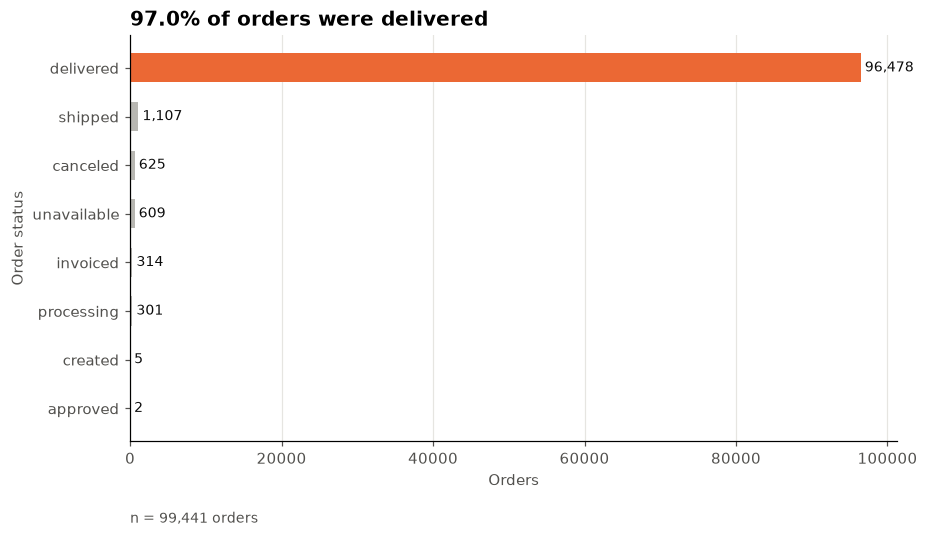

Takeaway: 97.0% delivered; no other status is above 1.1% of orders.


In [6]:
# CHART 4: How many orders are in each status?
status = df["order_status"].value_counts().sort_values()   # sorted so the biggest bar ends up on top
delivered_pct = status["delivered"] / len(df) * 100

fig, ax = plt.subplots()
colors = [ORANGE if s == "delivered" else GREY for s in status.index]   # highlight the main status
ax.barh(status.index, status.values, color=colors, height=0.6)
for y, v in enumerate(status.values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9, color="#0b0b0b")  # value at the end of each bar
ax.set_title(f"{delivered_pct:.1f}% of orders were delivered")
ax.set_xlabel("Orders")
ax.set_ylabel("Order status")
ax.grid(axis="y", visible=False)
ax.text(0, -0.2, f"n = {len(df):,} orders", transform=ax.transAxes, fontsize=9, color="#52514e")
save(fig, "04_order_status.png")
plt.show()

other_max = status.drop("delivered").max() / len(df) * 100
print(f"Takeaway: {delivered_pct:.1f}% delivered; no other status is above {other_max:.1f}% of orders.")

**Takeaway (Chart 4):** **97.0%** of orders were delivered. No other status is above 1.1% (shipped 1,107; canceled 625; unavailable 609). Orders still `shipped`, `invoiced`, `processing`, `created` or `approved` have no final outcome and should not be counted as late or cancelled.

## Chart 5: Cancellation share

Saved: C:\Users\charv\Documents\qveto\Ecommerce\reports\figures\05_cancellation_share.png


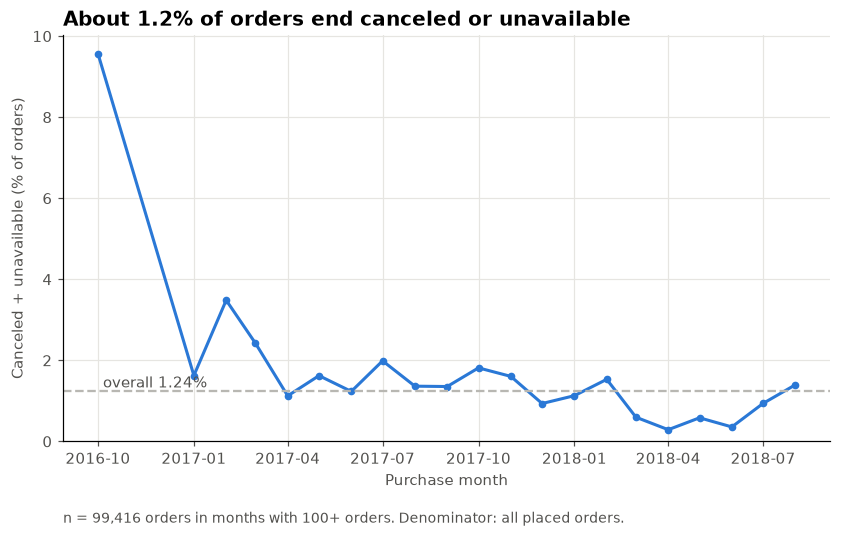

Takeaway: 1.24% of all orders were canceled or unavailable; highest month: 2016-10 (9.57%).


In [7]:
# CHART 5: What share of orders were cancelled or unavailable, and is it stable over time?
# Denominator = ALL placed orders (as the KPI guide asks us to state)
df["month"] = df["order_purchase_timestamp"].dt.to_period("M")
by_month = df.groupby("month").agg(orders=("order_id", "size"),
                                   canceled=("order_status", lambda s: (s == "canceled").sum()),
                                   unavailable=("order_status", lambda s: (s == "unavailable").sum()))
by_month = by_month[by_month["orders"] >= 100]             # skip tiny partial months (misleading %)
by_month["cancel_pct"] = (by_month["canceled"] + by_month["unavailable"]) / by_month["orders"] * 100

overall_cancel = df["order_status"].isin(["canceled", "unavailable"]).mean() * 100

fig, ax = plt.subplots()
ax.plot(by_month.index.to_timestamp(), by_month["cancel_pct"], color=BLUE, linewidth=2, marker="o", markersize=4)
ax.axhline(overall_cancel, color=GREY, linewidth=1.5, linestyle="--")
ax.text(by_month.index.to_timestamp()[0], overall_cancel, f" overall {overall_cancel:.2f}%", va="bottom", color="#52514e")
ax.set_title(f"About {overall_cancel:.1f}% of orders end canceled or unavailable")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Canceled + unavailable (% of orders)")
ax.set_ylim(bottom=0)
ax.text(0, -0.2, f"n = {by_month['orders'].sum():,} orders in months with 100+ orders. Denominator: all placed orders.",
        transform=ax.transAxes, fontsize=9, color="#52514e")
save(fig, "05_cancellation_share.png")
plt.show()

print(f"Takeaway: {overall_cancel:.2f}% of all orders were canceled or unavailable; highest month: "
      f"{by_month['cancel_pct'].idxmax()} ({by_month['cancel_pct'].max():.2f}%).")

**Takeaway (Chart 5):** **1.24%** of all placed orders ended canceled or unavailable (denominator: all 99,441 orders). The highest month, Oct 2016 (9.57%), had only ~324 orders, so it is a **low-volume early-platform effect**, not a trend. From 2017 the share stays around 1–2%.

## Chart 6: Rating distribution

Saved: C:\Users\charv\Documents\qveto\Ecommerce\reports\figures\06_rating_distribution.png


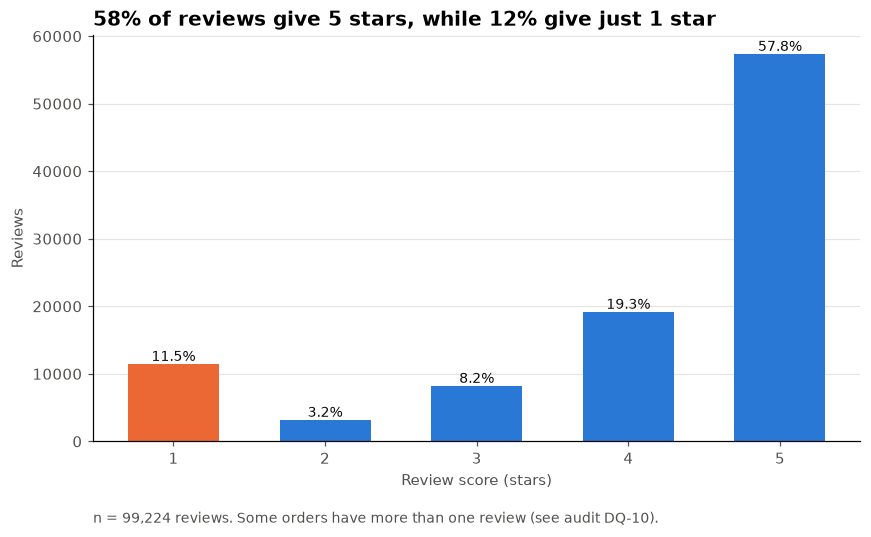

Takeaway: 57.8% five-star vs 11.5% one-star. M3/M4 will test whether late orders are associated with low ratings.


In [8]:
# CHART 6: How do customers rate their orders (1-5 stars)?
ratings = reviews["review_score"].value_counts().sort_index()   # 1, 2, 3, 4, 5 in order
pct = ratings / ratings.sum() * 100

fig, ax = plt.subplots()
colors = [ORANGE if s == 1 else BLUE for s in ratings.index]    # highlight 1-star reviews
ax.bar(ratings.index.astype(str), ratings.values, color=colors, width=0.6)
for x, (v, p_) in enumerate(zip(ratings.values, pct.values)):
    ax.text(x, v, f"{p_:.1f}%", ha="center", va="bottom", fontsize=9, color="#0b0b0b")
ax.set_title(f"{pct[5]:.0f}% of reviews give 5 stars, while {pct[1]:.0f}% give just 1 star")
ax.set_xlabel("Review score (stars)")
ax.set_ylabel("Reviews")
ax.grid(axis="x", visible=False)
ax.text(0, -0.2, f"n = {ratings.sum():,} reviews. Some orders have more than one review (see audit DQ-10).",
        transform=ax.transAxes, fontsize=9, color="#52514e")
save(fig, "06_rating_distribution.png")
plt.show()

print(f"Takeaway: {pct[5]:.1f}% five-star vs {pct[1]:.1f}% one-star. M3/M4 will test whether late orders are associated with low ratings.")

**Takeaway (Chart 6):** Customers are mostly positive: **57.8%** of reviews give 5 stars and 19.3% give 4. But **11.5% give just 1 star**, more than 2-star and 3-star reviews combined. M3/M4 will test whether late deliveries are *associated with* these low ratings (n = 99,224 reviews; 547 orders have more than one review).

## Chart 7: Missing key dates

Saved: C:\Users\charv\Documents\qveto\Ecommerce\reports\figures\07_missing_key_dates.png


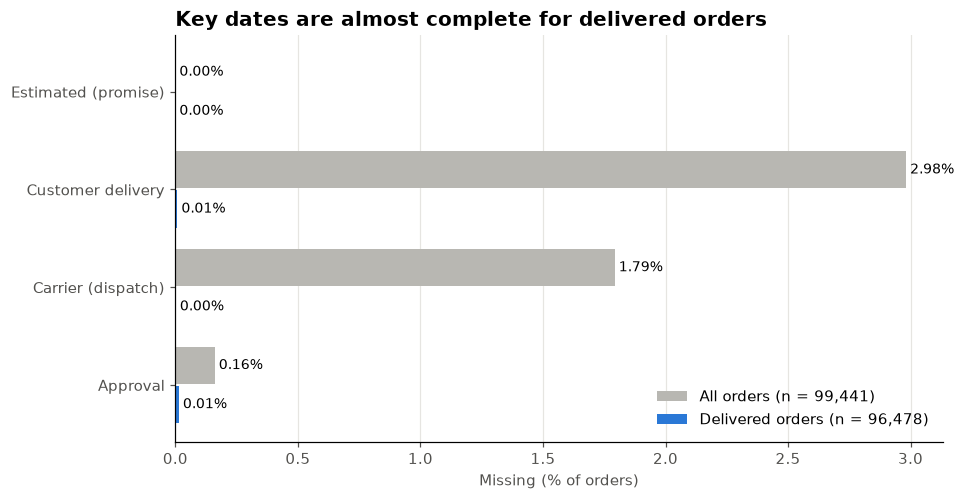

Takeaway: most missing delivery dates belong to orders that were never delivered; for delivered orders, gaps are tiny (audit DQ-01, DQ-03, DQ-04).


,All orders,Delivered orders
Approval,0.16,0.01
Carrier (dispatch),1.79,0.00
Customer delivery,2.98,0.01
Estimated (promise),0.00,0.00


In [9]:
# CHART 7: How complete are the key dates?
# Shown for ALL orders and for DELIVERED orders only (missing dates matter most for delivered ones)
labels = {"order_approved_at": "Approval", "order_delivered_carrier_date": "Carrier (dispatch)",
          "order_delivered_customer_date": "Customer delivery", "order_estimated_delivery_date": "Estimated (promise)"}
delivered = df[df["order_status"] == "delivered"]
miss = pd.DataFrame({
    "All orders": df[list(labels)].isna().mean() * 100,
    "Delivered orders": delivered[list(labels)].isna().mean() * 100,
}).rename(index=labels)

fig, ax = plt.subplots()
y = range(len(miss))
ax.barh([i + 0.2 for i in y], miss["All orders"], height=0.38, color=GREY, label=f"All orders (n = {len(df):,})")
ax.barh([i - 0.2 for i in y], miss["Delivered orders"], height=0.38, color=BLUE, label=f"Delivered orders (n = {len(delivered):,})")
for i, (a, b) in enumerate(zip(miss["All orders"], miss["Delivered orders"])):
    ax.text(a, i + 0.2, f" {a:.2f}%", va="center", fontsize=9)
    ax.text(b, i - 0.2, f" {b:.2f}%", va="center", fontsize=9)
ax.set_yticks(list(y))
ax.set_yticklabels(miss.index)
ax.set_title("Key dates are almost complete for delivered orders")
ax.set_xlabel("Missing (% of orders)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
save(fig, "07_missing_key_dates.png")
plt.show()

print("Takeaway: most missing delivery dates belong to orders that were never delivered; for delivered orders, gaps are tiny (audit DQ-01, DQ-03, DQ-04).")
miss.round(2)

**Takeaway (Chart 7):** Across all orders, 2.98% have no customer delivery date and 1.79% no dispatch date, but almost all of these are orders that were **never delivered**. For delivered orders, every key date is ≥ 99.99% complete (only 8, 2 and 14 orders missing: audit DQ-01, DQ-03, DQ-04). The promised (estimated) date is 100% complete, so the **on-time KPI can be measured reliably**.

## Initial findings (for M3, M4, M6)

1. **Volume:** orders grew through 2017 and peaked in Nov 2017 (7,544). Months at the dataset edges (under 100 orders) are partial and should not be read as trends.
2. **Where the time goes:** median delivery is 10.2 days but median processing (purchase → courier) is only 2.2 days, so **transit is the larger share** of delivery time. M4 to confirm for late orders.
3. **Cancellation:** 1.24% of all placed orders end canceled or unavailable (denominator = all orders). The Oct 2016 spike (9.57%) is a low-volume effect.
4. **Ratings:** 57.8% five-star vs 11.5% one-star. Open question for M3/M4: are late deliveries *associated with* the 1-star group?
5. **Data completeness:** key dates are ≥ 99.99% complete for delivered orders, and the promised date is 100% complete, so delivery KPIs rest on solid data.

*All findings are descriptive associations, not causes.*